In [9]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

In [10]:
df=pd.read_csv(r'/Users/HP/Desktop/3rd Year Personal/AIML/Vehicle Count Prediction/delhi_traffic_features.csv')
df.head()

,Trip_ID,start_area,end_area,distance_km,time_of_day,day_of_week,weather_condition,traffic_density_level,road_type,average_speed_kmph
0,TRIP_00001,Vasant Kunj,Kalkaji,9.44,Night,Weekday,Clear,Low,Main Road,37.8
1,TRIP_00002,Greater Kailash,Kalkaji,2.15,Night,Weekend,Clear,Low,Main Road,42.7
2,TRIP_00003,Janakpuri,Model Town,14.54,Morning Peak,Weekday,Rain,High,Inner Road,9.7
3,TRIP_00004,Punjabi Bagh,Dwarka,11.86,Night,Weekday,Clear,Low,Highway,68.5
4,TRIP_00005,Rohini,Chandni Chowk,20.26,Afternoon,Weekday,Fog,Medium,Highway,30.3


In [11]:
coordinates = {
    "Kalkaji": (28.5354, 77.2639),
    "Janakpuri": (28.6219, 77.0878),
    "Rajouri Garden": (28.6490, 77.1227),
    "Noida Sector 18": (28.5708, 77.3261),
    "Greater Kailash": (28.5493, 77.2424),
    "Hauz Khas": (28.5494, 77.2001),
    "Okhla": (28.5429, 77.2750),
    "Model Town": (28.7027, 77.1935),
    "Chandni Chowk": (28.6506, 77.2303),
    "IGI Airport": (28.5562, 77.1000),
    "Vasant Kunj": (28.5207, 77.1588),
    "Preet Vihar": (28.6415, 77.2956),
    "Shahdara": (28.6733, 77.2897),
    "Mayur Vihar": (28.6042, 77.2935),
    "Dwarka": (28.5921, 77.0460),
    "Pitampura": (28.7033, 77.1322),
    "Punjabi Bagh": (28.6689, 77.1325),
    "Lajpat Nagar": (28.5677, 77.2433),
    "AIIMS": (28.5672, 77.2100),
    "Rohini": (28.7432, 77.0678),
    "Karol Bagh": (28.6514, 77.1907),
    "Civil Lines": (28.6769, 77.2250),
    "Saket": (28.5244, 77.2066),
    "Nehru Place": (28.5491, 77.2519),
    "Connaught Place": (28.6331, 77.2211)
}

In [12]:
df["start_lat"]=df["start_area"].map(lambda x: coordinates.get(x, (None, None))[0])
df["start_lon"]=df["start_area"].map(lambda x: coordinates.get(x, (None, None))[1])

df["end_lat"]=df["end_area"].map(lambda x: coordinates.get(x, (None, None))[0])
df["end_lon"]=df["end_area"].map(lambda x: coordinates.get(x, (None, None))[1])

In [13]:
print(df[["start_area", "start_lat", "start_lon", "end_area", "end_lat", "end_lon"]].head())

        start_area  start_lat  start_lon       end_area  end_lat  end_lon
0      Vasant Kunj    28.5207    77.1588        Kalkaji  28.5354  77.2639
1  Greater Kailash    28.5493    77.2424        Kalkaji  28.5354  77.2639
2        Janakpuri    28.6219    77.0878     Model Town  28.7027  77.1935
3     Punjabi Bagh    28.6689    77.1325         Dwarka  28.5921  77.0460
4           Rohini    28.7432    77.0678  Chandni Chowk  28.6506  77.2303


In [14]:
df.to_csv("delhi_traffic_coordinates.csv", index=False)         #to_csv() converts your DataFrame into a CSV file.

In [15]:
df[["start_lat", "start_lon", "end_lat", "end_lon"]].isna().sum()

start_lat    0
start_lon    0
end_lat      0
end_lon      0
dtype: int64

In [16]:
df["average_speed_kmph"]=pd.to_numeric(df["average_speed_kmph"], errors="coerce")
df["distance_km"]=pd.to_numeric(df["distance_km"], errors="coerce")

df["travel_time"]=np.where((df["average_speed_kmph"]>0)&(df["distance_km"]>0), (df["distance_km"] / df["average_speed_kmph"])*60, np.nan)
df.to_csv("delhi_traffic_coordinates.csv", index=False)

In [17]:
data=pd.read_csv(r'/Users/HP/Desktop/3rd Year Personal/AIML/Vehicle Count Prediction/delhi_traffic_coordinates.csv')
data.head()

,Trip_ID,start_area,end_area,distance_km,time_of_day,day_of_week,weather_condition,traffic_density_level,road_type,average_speed_kmph,start_lat,start_lon,end_lat,end_lon,travel_time
0,TRIP_00001,Vasant Kunj,Kalkaji,9.44,Night,Weekday,Clear,Low,Main Road,37.8,28.5207,77.1588,28.5354,77.2639,14.984127
1,TRIP_00002,Greater Kailash,Kalkaji,2.15,Night,Weekend,Clear,Low,Main Road,42.7,28.5493,77.2424,28.5354,77.2639,3.021077
2,TRIP_00003,Janakpuri,Model Town,14.54,Morning Peak,Weekday,Rain,High,Inner Road,9.7,28.6219,77.0878,28.7027,77.1935,89.938144
3,TRIP_00004,Punjabi Bagh,Dwarka,11.86,Night,Weekday,Clear,Low,Highway,68.5,28.6689,77.1325,28.5921,77.0460,10.388321
4,TRIP_00005,Rohini,Chandni Chowk,20.26,Afternoon,Weekday,Fog,Medium,Highway,30.3,28.7432,77.0678,28.6506,77.2303,40.118812


In [18]:
data.shape

(4000, 15)

In [19]:
data["travel_time"].describe()

count    4000.000000
mean       39.031446
std        31.021046
min         2.201835
25%        18.000000
50%        29.553062
75%        50.690625
max       279.346154
Name: travel_time, dtype: float64

In [20]:
from sklearn.model_selection import train_test_split
features=["start_lat", "start_lon", "end_lat", "end_lon"]

X=data[features]
y=data["travel_time"]

valid=X.notna().all(axis=1) & y.notna() & (y>=0)
X=X.loc[valid]
y=y.loc[valid]

X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
print("Training: ", len(X_train))
print("Testing: ", len(X_test))

Training:  3200
Testing:  800


In [22]:
from sklearn.ensemble import RandomForestRegressor
model=RandomForestRegressor(n_estimators=100, random_state=42)

model.fit(X_train, y_train)
y_pred=model.predict(X_test)
print(y_pred[:10])

[31.37425829 30.57261445 32.73168896 14.85720283 75.55035336 46.39020574
 11.81498214 29.61215472 18.79907364 17.92075703]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae=mean_absolute_error(y_test, y_pred)
rmse=np.sqrt(mean_squared_error(y_test, y_pred))
r2=r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f} minutes")
print(f"RMSE: {rmse:.2f} minutes")
print(f"R²:   {r2:.3f}")

MAE:  20.82 minutes
RMSE: 28.40 minutes
R²:   -0.013


In [24]:
print(data["travel_time"].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]))
print(data.nsmallest(10, "travel_time")[["start_area", "end_area", "distance_km", "average_speed_kmph", "travel_time"]])
print(data.nlargest(10, "travel_time")[["start_area", "end_area", "distance_km", "average_speed_kmph", "travel_time"]])

count    4000.000000
mean       39.031446
std        31.021046
min         2.201835
25%        18.000000
50%        29.553062
75%        50.690625
90%        80.209811
95%       102.513806
99%       151.951581
max       279.346154
Name: travel_time, dtype: float64
           start_area      end_area  distance_km  average_speed_kmph  \
2296      Nehru Place  Lajpat Nagar         2.80                76.3   
3938          Kalkaji   Nehru Place         1.51                36.9   
3649      Nehru Place       Kalkaji         1.51                35.7   
3677          Kalkaji   Nehru Place         1.51                30.6   
1     Greater Kailash       Kalkaji         2.15                42.7   
999       Nehru Place  Lajpat Nagar         2.80                55.1   
2173            AIIMS     Hauz Khas         2.20                42.4   
3966      Nehru Place         Okhla         2.67                51.0   
1974      Nehru Place         Okhla         2.67                50.5   
363   Greater K

In [25]:
route_stats=data.groupby(["start_area", "end_area"])["travel_time"].agg(["count", "mean", "std"])
print(route_stats.sort_values("std", ascending=False).head(10))

                                 count       mean        std
start_area      end_area                                    
IGI Airport     Model Town           6  73.439583  76.890151
Noida Sector 18 Rohini               7  85.776276  73.223203
Rohini          Shahdara            12  69.919162  70.966106
Shahdara        Rohini               7  67.815522  70.703251
Noida Sector 18 Dwarka               7  63.293957  69.858446
Model Town      Nehru Place          6  85.616423  69.780364
Karol Bagh      Greater Kailash      3  78.672462  68.296462
Pitampura       Vasant Kunj          4  54.049395  67.401255
Nehru Place     Rohini               9  85.717622  66.100826
Pitampura       Nehru Place          6  75.387448  65.909147


In [26]:
print(data["time_of_day"].unique())
print(data["weather_condition"].unique())
print(data["day_of_week"].unique())


['Night' 'Morning Peak' 'Afternoon' 'Evening Peak']
['Clear' 'Rain' 'Fog' 'Heatwave']
['Weekday' 'Weekend']


In [27]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor

# Use the same features for every model
numeric_features = [
    "start_lat", "start_lon",
    "end_lat", "end_lon",
    "distance_km"
]

categorical_features = [
    "time_of_day",
    "weather_condition",
    "day_of_week"
]

X = data[numeric_features + categorical_features]
y = data["travel_time"]

valid = X.notna().all(axis=1) & y.notna() & (y >= 0)
X, y = X.loc[valid], y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []

for name, regressor in models.items():
    preprocessor = ColumnTransformer([
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ], remainder="passthrough")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
print(results_df.round(3).to_string(index=False))


            Model    MAE   RMSE    R2
Gradient Boosting 17.151 23.745 0.292
Linear Regression 17.687 23.774 0.290
    Random Forest 18.561 25.611 0.176
      Extra Trees 19.663 27.979 0.017


In [28]:
from sklearn.model_selection import KFold, cross_validate
preprocessor = ColumnTransformer([
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
], remainder="passthrough")

model=Pipeline([("preprocessor", preprocessor), ("regressor", GradientBoostingRegressor(random_state=42))])

cv=KFold(n_splits=5, shuffle=True, random_state=42)

scores=cross_validate(model, X, y, cv=cv, scoring={
    "mae":"neg_mean_absolute_error",
    "rmse":"neg_root_mean_squared_error",
    "r2":"r2"
})

print(f"Mean MAE:  {-scores['test_mae'].mean():.3f} minutes")
print(f"Mean RMSE: {-scores['test_rmse'].mean():.3f} minutes")
print(f"Mean R²:    {scores['test_r2'].mean():.3f}")

print("\nScores across individual folds:")
for i in range(5):
    print(
        f"Fold {i+1}: "
        f"MAE={-scores['test_mae'][i]:.3f}, "
        f"RMSE={-scores['test_rmse'][i]:.3f}, "
        f"R²={scores['test_r2'][i]:.3f}"
    )


Mean MAE:  17.338 minutes
Mean RMSE: 24.790 minutes
Mean R²:    0.356

Scores across individual folds:
Fold 1: MAE=17.164, RMSE=23.744, R²=0.292
Fold 2: MAE=17.904, RMSE=26.138, R²=0.346
Fold 3: MAE=16.965, RMSE=23.912, R²=0.365
Fold 4: MAE=17.474, RMSE=25.953, R²=0.409
Fold 5: MAE=17.185, RMSE=24.200, R²=0.369


In [29]:
from sklearn.model_selection import RandomizedSearchCV

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(random_state=42))
])

param_distributions = {
    "regressor__n_estimators": [100, 200, 300, 500],
    "regressor__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "regressor__max_depth": [2, 3, 4, 5],
    "regressor__min_samples_split": [2, 5, 10, 20],
    "regressor__min_samples_leaf": [1, 2, 4, 8],
    "regressor__subsample": [0.7, 0.85, 1.0]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=40,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X, y)

print("Best CV MAE:", round(-search.best_score_, 3), "minutes")
print("Best parameters:")
print(search.best_params_)


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best CV MAE: 17.267 minutes
Best parameters:
{'regressor__subsample': 1.0, 'regressor__n_estimators': 100, 'regressor__min_samples_split': 20, 'regressor__min_samples_leaf': 8, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.05}


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

best_model = search.best_estimator_
best_model.fit(X_train, y_train)

predictions = best_model.predict(X_test)

print(f"Test MAE:  {mean_absolute_error(y_test, predictions):.3f} minutes")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, predictions)):.3f} minutes")
print(f"Test R²:   {r2_score(y_test, predictions):.3f}")

Test MAE:  16.850 minutes
Test RMSE: 23.141 minutes
Test R²:   0.327


In [31]:
print("Unique routes:", data[["start_area", "end_area"]].drop_duplicates().shape[0])
route_counts=data.groupby(["start_area", "end_area"]).size()
print(route_counts.describe())
print("routes with one observation", (route_counts==1).sum())

Unique routes: 600
count    600.000000
mean       6.666667
std        2.382229
min        1.000000
25%        5.000000
50%        6.000000
75%        8.000000
max       15.000000
dtype: float64
routes with one observation 4


In [32]:
from sklearn.model_selection import GroupShuffleSplit
groups = data.loc[X.index, "start_area"] + " -> " + data.loc[X.index, "end_area"]

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

best_model.fit(X_train, y_train)
predictions = best_model.predict(X_test)

print(f"Unseen-route MAE:  {mean_absolute_error(y_test, predictions):.3f} minutes")
print(f"Unseen-route RMSE: {np.sqrt(mean_squared_error(y_test, predictions)):.3f} minutes")
print(f"Unseen-route R²:   {r2_score(y_test, predictions):.3f}")

Unseen-route MAE:  17.959 minutes
Unseen-route RMSE: 25.208 minutes
Unseen-route R²:   0.384


In [33]:
groups = data.loc[X.index, "start_area"]

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

best_model.fit(X_train, y_train)
predictions = best_model.predict(X_test)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Held-out start areas:", groups.iloc[test_idx].nunique())

print(f"MAE:  {mean_absolute_error(y_test, predictions):.3f} minutes")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predictions)):.3f} minutes")
print(f"R²:   {r2_score(y_test, predictions):.3f}")

Training rows: 3229
Test rows: 771
Held-out start areas: 5
MAE:  16.481 minutes
RMSE: 23.054 minutes
R²:   0.407


In [34]:
all_areas = sorted(
    set(data.loc[X.index, "start_area"]) |
    set(data.loc[X.index, "end_area"])
)

rng = np.random.RandomState(42)
held_out_areas = set(rng.choice(all_areas, size=5, replace=False))

start = data.loc[X.index, "start_area"]
end = data.loc[X.index, "end_area"]

# Test: both endpoints must be held-out areas
test_mask = start.isin(held_out_areas) & end.isin(held_out_areas)

# Train: neither endpoint can be a held-out area
train_mask = ~start.isin(held_out_areas) & ~end.isin(held_out_areas)

train_idx = np.where(train_mask)[0]
test_idx = np.where(test_mask)[0]

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Held-out areas:", sorted(held_out_areas))
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

if len(X_test) == 0:
    print("No trips between held-out areas. Choose more held-out areas.")
else:
    best_model.fit(X_train, y_train)
    predictions = best_model.predict(X_test)

    print(f"MAE:  {mean_absolute_error(y_test, predictions):.3f} minutes")
    print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predictions)):.3f} minutes")
    print(f"R²:   {r2_score(y_test, predictions):.3f}")

Held-out areas: [np.str_('AIIMS'), np.str_('Janakpuri'), np.str_('Lajpat Nagar'), np.str_('Okhla'), np.str_('Shahdara')]
Training rows: 2535
Test rows: 110
MAE:  18.613 minutes
RMSE: 26.566 minutes
R²:   0.406


In [35]:
print(data["average_speed_kmph"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
))

print("\nLowest 10 speeds:")
print(data.nsmallest(10, "average_speed_kmph")[
    ["start_area", "end_area", "distance_km",
     "average_speed_kmph", "travel_time"]
])

print("\nHighest 10 speeds:")
print(data.nlargest(10, "average_speed_kmph")[
    ["start_area", "end_area", "distance_km",
     "average_speed_kmph", "travel_time"]
])

count    4000.000000
mean       28.085300
std        17.057224
min         4.800000
1%          5.699000
5%          8.100000
25%        14.500000
50%        24.200000
75%        38.200000
95%        61.605000
99%        81.200000
max        93.300000
Name: average_speed_kmph, dtype: float64

Lowest 10 speeds:
        start_area         end_area  distance_km  average_speed_kmph  \
167    IGI Airport      Vasant Kunj         6.90                 4.8   
171          AIIMS            Saket         4.77                 4.8   
443    Vasant Kunj      Nehru Place         9.97                 4.8   
1130   Vasant Kunj            AIIMS         7.41                 4.8   
1556         AIIMS            Saket         4.77                 4.8   
1695         AIIMS  Greater Kailash         3.26                 4.8   
1758         Okhla          Kalkaji         1.94                 4.8   
2000  Lajpat Nagar            Saket         5.89                 4.8   
787          Saket        Hauz Khas     

In [36]:
print(data.groupby("traffic_density_level")[
    "average_speed_kmph"
].agg(["count", "mean", "median", "min", "max"]).round(2))

print("\nSpeed by time of day:")
print(data.groupby("time_of_day")[
    "average_speed_kmph"
].agg(["count", "mean", "median", "min", "max"]).round(2))

print("\nSpeed by weather:")
print(data.groupby("weather_condition")[
    "average_speed_kmph"
].agg(["count", "mean", "median", "min", "max"]).round(2))

                       count   mean  median   min   max
traffic_density_level                                  
High                    1348  24.21   23.05   7.6  46.2
Low                      618  46.95   43.55  10.2  93.3
Medium                  1055  36.54   35.10   7.7  69.2
Very High                979  12.41   11.60   4.8  23.6

Speed by time of day:
              count   mean  median  min   max
time_of_day                                  
Afternoon      1057  32.66   30.00  4.9  89.7
Evening Peak   1397  22.97   19.20  4.8  89.4
Morning Peak   1150  25.72   21.50  4.8  87.2
Night           396  40.82   37.85  9.3  93.3

Speed by weather:
                   count   mean  median  min   max
weather_condition                                 
Clear               2382  31.24    27.7  7.6  93.3
Fog                  411  17.24    15.6  4.8  49.4
Heatwave             608  28.65    25.4  7.7  87.1
Rain                 599  22.40    20.1  4.8  63.2


In [37]:
# Check repeated speed values
print("Most common speeds:")
print(data["average_speed_kmph"].value_counts().head(15))

# Verify the travel-time formula
calculated_time = (
    data["distance_km"] / data["average_speed_kmph"]
) * 60

difference = (data["travel_time"] - calculated_time).abs()

print("\nDifference from calculated travel time:")
print(difference.describe())

print("\nRows with difference > 0.01 minutes:", (difference > 0.01).sum())


Most common speeds:
average_speed_kmph
8.0     34
8.3     28
7.8     26
8.2     26
8.1     23
7.7     22
11.8    21
11.6    19
13.4    19
28.7    19
20.7    19
13.1    19
7.9     18
13.8    18
21.1    17
Name: count, dtype: int64

Difference from calculated travel time:
count    4.000000e+03
mean     5.875300e-16
std      2.375289e-15
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.842171e-14
dtype: float64

Rows with difference > 0.01 minutes: 0


In [38]:
print(
    data.nlargest(15, "travel_time")[
        [
            "start_area",
            "end_area",
            "distance_km",
            "average_speed_kmph",
            "travel_time",
            "time_of_day",
            "weather_condition",
            "traffic_density_level"
        ]
    ].to_string(index=False)
)

     start_area    end_area  distance_km  average_speed_kmph  travel_time  time_of_day weather_condition traffic_density_level
         Rohini    Shahdara        24.21                 5.2   279.346154 Evening Peak               Fog             Very High
Noida Sector 18      Rohini        33.01                 8.2   241.536585 Evening Peak             Clear             Very High
          Saket      Rohini        29.00                 7.7   225.974026 Evening Peak             Clear             Very High
    Preet Vihar IGI Airport        21.04                 5.6   225.428571 Evening Peak               Fog             Very High
    IGI Airport  Model Town        19.83                 5.3   224.490566 Morning Peak               Fog             Very High
    Nehru Place  Model Town        19.38                 5.2   223.615385 Evening Peak               Fog             Very High
    Nehru Place      Rohini        29.42                 7.9   223.443038 Evening Peak             Clear       

In [39]:
import joblib
best_model = search.best_estimator_
best_model.fit(X, y)

joblib.dump(best_model, "delhi_travel_time_model.pkl")

['delhi_travel_time_model.pkl']

In [40]:


# Save the trained model and preprocessing pipeline
joblib.dump(best_model, "delhi_travel_time_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [41]:
model = joblib.load("delhi_travel_time_model.pkl")

def predict_travel_time(
    start_lat,
    start_lon,
    end_lat,
    end_lon,
    distance_km,  # OSRM will supply this later
    time_of_day,
    weather_condition,
    day_of_week
):
    trip = pd.DataFrame([{
        "start_lat": start_lat,
        "start_lon": start_lon,
        "end_lat": end_lat,
        "end_lon": end_lon,
        "distance_km": distance_km,
        "time_of_day": time_of_day,
        "weather_condition": weather_condition,
        "day_of_week": day_of_week
    }])

    predicted_minutes = model.predict(trip)[0]

    return round(float(predicted_minutes), 2)

In [42]:

example = data.iloc[0]

predicted_minutes = predict_travel_time(
    start_lat=example["start_lat"],
    start_lon=example["start_lon"],
    end_lat=example["end_lat"],
    end_lon=example["end_lon"],
    distance_km=example["distance_km"],  # Placeholder until OSRM integration
    time_of_day=example["time_of_day"],
    weather_condition=example["weather_condition"],
    day_of_week=example["day_of_week"]
)

print(f"Predicted travel time: {predicted_minutes} minutes")
print(f"Dataset target: {example['travel_time']:.2f} minutes")


Predicted travel time: 17.65 minutes
Dataset target: 14.98 minutes


In [43]:

# Enter your trip details
start_lat = 28.5899
start_lon = 77.0702

end_lat = 28.6425
end_lon = 77.1217
distance_km = 10.6  # Replace manually until OSRM is connected

time_of_day = "Night"
weather_condition = "Clear"
day_of_week = "Weekday"

# Get prediction
predicted_minutes = predict_travel_time(
    start_lat=start_lat,
    start_lon=start_lon,
    end_lat=end_lat,
    end_lon=end_lon,
    distance_km=distance_km,
    time_of_day=time_of_day,
    weather_condition=weather_condition,
    day_of_week=day_of_week
)

print(f"Predicted travel time: {predicted_minutes:.2f} minutes")
print(f"Approximately {predicted_minutes / 60:.2f} hours")


Predicted travel time: 18.05 minutes
Approximately 0.30 hours


In [44]:

# Five trips using areas in the training dataset
seen_trips = {
    "Seen 1": {
        "start": "Connaught Place",
        "end": "IGI Airport",
        "distance_km": 16,
        "time_of_day": "Morning Peak",
        "weather_condition": "Clear",
        "day_of_week": "Weekday"
    },
    "Seen 2": {
        "start": "Rohini",
        "end": "Saket",
        "distance_km": 25,
        "time_of_day": "Evening Peak",
        "weather_condition": "Rain",
        "day_of_week": "Weekday"
    },
    "Seen 3": {
        "start": "Dwarka",
        "end": "Noida Sector 18",
        "distance_km": 28,
        "time_of_day": "Afternoon",
        "weather_condition": "Clear",
        "day_of_week": "Weekend"
    },
    "Seen 4": {
        "start": "AIIMS",
        "end": "Hauz Khas",
        "distance_km": 6,
        "time_of_day": "Night",
        "weather_condition": "Clear",
        "day_of_week": "Weekend"
    },
    "Seen 5": {
        "start": "Karol Bagh",
        "end": "Lajpat Nagar",
        "distance_km": 11,
        "time_of_day": "Evening Peak",
        "weather_condition": "Fog",
        "day_of_week": "Weekday"
    }
}

# Five trips between landmarks not in the training dataset
unseen_trips = {
    "Unseen 1": {
        "start": "India Gate",
        "start_lat": 28.6129,
        "start_lon": 77.2296,
        "end": "Red Fort",
        "end_lat": 28.6555,
        "end_lon": 77.2410,
        "distance_km": 7,
        "time_of_day": "Morning Peak",
        "weather_condition": "Clear",
        "day_of_week": "Weekend"
    },
    "Unseen 2": {
        "start": "Lotus Temple",
        "start_lat": 28.5533,
        "start_lon": 77.2585,
        "end": "Akshardham",
        "end_lat": 28.6125,
        "end_lon": 77.2772,
        "distance_km": 15,
        "time_of_day": "Evening Peak",
        "weather_condition": "Rain",
        "day_of_week": "Weekday"
    },
    "Unseen 3": {
        "start": "Jama Masjid",
        "start_lat": 28.6507,
        "start_lon": 77.2334,
        "end": "India Gate",
        "end_lat": 28.6129,
        "end_lon": 77.2296,
        "distance_km": 6,
        "time_of_day": "Afternoon",
        "weather_condition": "Heatwave",
        "day_of_week": "Weekday"
    },
    "Unseen 4": {
        "start": "Red Fort",
        "start_lat": 28.6555,
        "start_lon": 77.2410,
        "end": "Lotus Temple",
        "end_lat": 28.5533,
        "end_lon": 77.2585,
        "distance_km": 17,
        "time_of_day": "Night",
        "weather_condition": "Clear",
        "day_of_week": "Weekend"
    },
    "Unseen 5": {
        "start": "Akshardham",
        "start_lat": 28.6125,
        "start_lon": 77.2772,
        "end": "Jama Masjid",
        "end_lat": 28.6507,
        "end_lon": 77.2334,
        "distance_km": 10,
        "time_of_day": "Morning Peak",
        "weather_condition": "Fog",
        "day_of_week": "Weekday"
    }
}


In [45]:

def get_area_coordinates(area):
    row = data.loc[data["start_area"] == area].iloc[0]
    return row["start_lat"], row["start_lon"]


def run_test_cases(trips, unseen=False):
    for case_name, trip in trips.items():

        if unseen:
            start_lat = trip["start_lat"]
            start_lon = trip["start_lon"]
            end_lat = trip["end_lat"]
            end_lon = trip["end_lon"]
        else:
            start_lat, start_lon = get_area_coordinates(trip["start"])
            end_lat, end_lon = get_area_coordinates(trip["end"])

        predicted = predict_travel_time(
            start_lat=start_lat,
            start_lon=start_lon,
            end_lat=end_lat,
            end_lon=end_lon,
            distance_km=trip["distance_km"],
            time_of_day=trip["time_of_day"],
            weather_condition=trip["weather_condition"],
            day_of_week=trip["day_of_week"]
        )

        conditions = (
            f'{trip["time_of_day"]}, '
            f'{trip["weather_condition"]}, '
            f'{trip["day_of_week"]}'
        )

        print(
            f'{trip["start"]} - {trip["end"]} - '
            f'{conditions}: {predicted:.2f} minutes'
        )


print("===== SEEN LOCATIONS =====")
run_test_cases(seen_trips)

print("\n===== UNSEEN LANDMARKS =====")
run_test_cases(unseen_trips, unseen=True)


===== SEEN LOCATIONS =====
Connaught Place - IGI Airport - Morning Peak, Clear, Weekday: 49.61 minutes
Rohini - Saket - Evening Peak, Rain, Weekday: 86.03 minutes
Dwarka - Noida Sector 18 - Afternoon, Clear, Weekend: 44.08 minutes
AIIMS - Hauz Khas - Night, Clear, Weekend: 11.51 minutes
Karol Bagh - Lajpat Nagar - Evening Peak, Fog, Weekday: 52.80 minutes

===== UNSEEN LANDMARKS =====
India Gate - Red Fort - Morning Peak, Clear, Weekend: 21.87 minutes
Lotus Temple - Akshardham - Evening Peak, Rain, Weekday: 58.27 minutes
Jama Masjid - India Gate - Afternoon, Heatwave, Weekday: 16.64 minutes
Red Fort - Lotus Temple - Night, Clear, Weekend: 23.95 minutes
Akshardham - Jama Masjid - Morning Peak, Fog, Weekday: 50.16 minutes


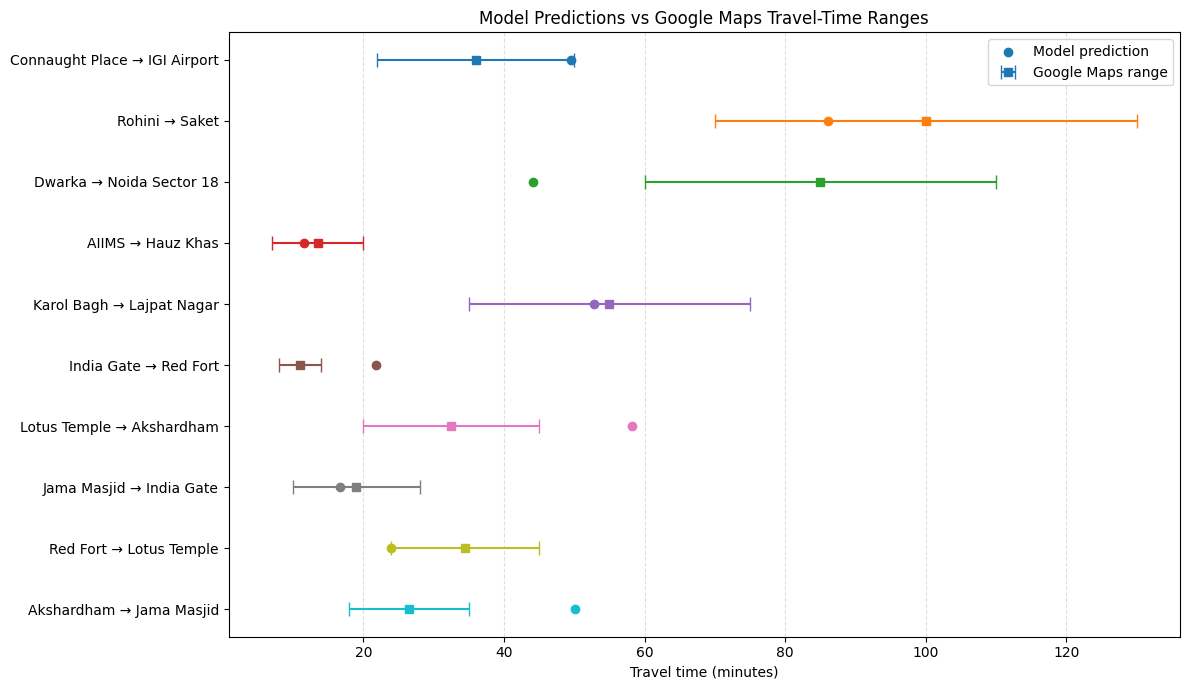

In [46]:

import matplotlib.pyplot as plt
import numpy as np

# Google Maps actual travel-time ranges (minutes)
actual_ranges = {
    "Seen 1": (22, 50),
    "Seen 2": (70, 130),
    "Seen 3": (60, 110),
    "Seen 4": (7, 20),
    "Seen 5": (35, 75),
    "Unseen 1": (8, 14),
    "Unseen 2": (20, 45),
    "Unseen 3": (10, 28),
    "Unseen 4": (24, 45),
    "Unseen 5": (18, 35)
}

# Re-run predictions and collect results
results = []

for group_name, trips, is_unseen in [
    ("Seen", seen_trips, False),
    ("Unseen", unseen_trips, True)
]:
    for case_name, trip in trips.items():

        if is_unseen:
            start_lat = trip["start_lat"]
            start_lon = trip["start_lon"]
            end_lat = trip["end_lat"]
            end_lon = trip["end_lon"]
        else:
            start_lat, start_lon = get_area_coordinates(trip["start"])
            end_lat, end_lon = get_area_coordinates(trip["end"])

        predicted = predict_travel_time(
            start_lat=start_lat,
            start_lon=start_lon,
            end_lat=end_lat,
            end_lon=end_lon,
            distance_km=trip["distance_km"],
            time_of_day=trip["time_of_day"],
            weather_condition=trip["weather_condition"],
            day_of_week=trip["day_of_week"]
        )

        actual_min, actual_max = actual_ranges[case_name]

        results.append({
            "case": case_name,
            "group": group_name,
            "route": f'{trip["start"]} → {trip["end"]}',
            "predicted": predicted,
            "actual_min": actual_min,
            "actual_max": actual_max
        })

# Sort and plot
results.sort(key=lambda row: (row["group"] != "Seen", row["case"]))

y_positions = np.arange(len(results))

fig, ax = plt.subplots(figsize=(12, 7))

for i, row in enumerate(results):
    midpoint = (row["actual_min"] + row["actual_max"]) / 2

    # Google Maps range: horizontal interval
    ax.errorbar(
        midpoint, i,
        xerr=[[
            midpoint - row["actual_min"]
        ], [
            row["actual_max"] - midpoint
        ]],
        fmt="s",
        capsize=5,
        label="Google Maps range" if i == 0 else None
    )

    # Model prediction
    ax.scatter(
        row["predicted"], i,
        marker="o",
        label="Model prediction" if i == 0 else None
    )

ax.set_yticks(y_positions)
ax.set_yticklabels([row["route"] for row in results])
ax.invert_yaxis()
ax.set_xlabel("Travel time (minutes)")
ax.set_title("Model Predictions vs Google Maps Travel-Time Ranges")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()


In [47]:

osrm_results = {
    "Seen 1":    {"distance_km": 19.5, "duration_min": 39},
    "Seen 2":    {"distance_km": 29.9, "duration_min": 57},
    "Seen 3":    {"distance_km": 30.9, "duration_min": 61},
    "Seen 4":    {"distance_km": 2.2,  "duration_min": 3},
    "Seen 5":    {"distance_km": 13.8, "duration_min": 33},
    "Unseen 1":  {"distance_km": 6.8,  "duration_min": 15},
    "Unseen 2":  {"distance_km": 11.4, "duration_min": 24},
    "Unseen 3":  {"distance_km": 6.3,  "duration_min": 13},
    "Unseen 4":  {"distance_km": 15.4, "duration_min": 31},
    "Unseen 5":  {"distance_km": 9.3,  "duration_min": 23}
}

# Update distances in the existing dictionaries
for case, values in osrm_results.items():
    if case.startswith("Seen"):
        seen_trips[case]["distance_km"] = values["distance_km"]
    else:
        unseen_trips[case]["distance_km"] = values["distance_km"]

print("OSRM distances added to all 10 test cases.")


OSRM distances added to all 10 test cases.


,Case,Route,OSRM Distance (km),Model (min),OSRM (min),Google Range (min),Model Within Google Range,Model Difference from OSRM (min),Outside Google Range (min)
0,Seen 1,Connaught Place → IGI Airport,19.5,54.24,39,22–50,False,15.24,4.24
1,Seen 2,Rohini → Saket,29.9,86.60,57,70–130,True,29.60,0.00
2,Seen 3,Dwarka → Noida Sector 18,30.9,54.64,61,60–110,False,-6.36,5.36
3,Seen 4,AIIMS → Hauz Khas,2.2,1.64,3,7–20,False,-1.36,5.36
4,Seen 5,Karol Bagh → Lajpat Nagar,13.8,62.83,33,35–75,True,29.83,0.00
5,Unseen 1,India Gate → Red Fort,6.8,21.87,15,8–14,False,6.87,7.87
6,Unseen 2,Lotus Temple → Akshardham,11.4,46.40,24,20–45,False,22.40,1.40
7,Unseen 3,Jama Masjid → India Gate,6.3,17.40,13,10–28,True,4.40,0.00
8,Unseen 4,Red Fort → Lotus Temple,15.4,22.49,31,24–45,False,-8.51,1.51
9,Unseen 5,Akshardham → Jama Masjid,9.3,50.29,23,18–35,False,27.29,15.29


Average absolute difference between model and OSRM: 15.19 minutes
Model predictions within Google Maps ranges: 3 / 10


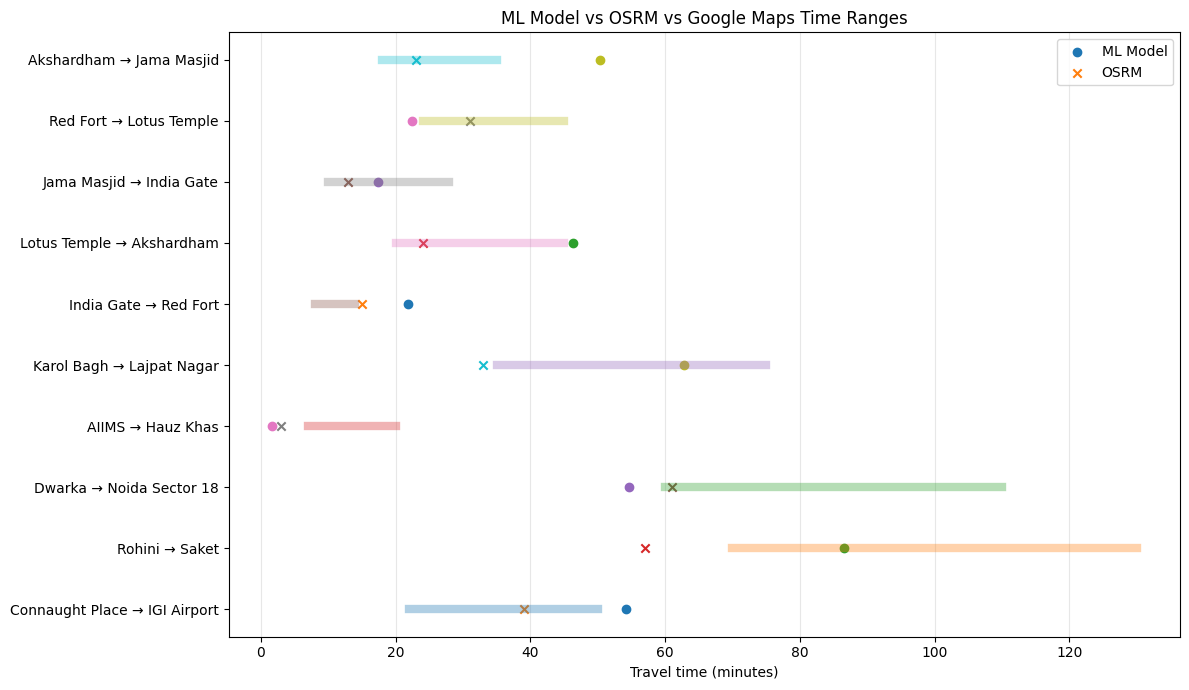

In [48]:
# Google Maps travel-time ranges (minutes)
google_ranges = {
    "Seen 1": (22, 50),
    "Seen 2": (70, 130),
    "Seen 3": (60, 110),
    "Seen 4": (7, 20),
    "Seen 5": (35, 75),
    "Unseen 1": (8, 14),
    "Unseen 2": (20, 45),
    "Unseen 3": (10, 28),
    "Unseen 4": (24, 45),
    "Unseen 5": (18, 35)
}

results = []

for group_name, trips in [
    ("Seen", seen_trips),
    ("Unseen", unseen_trips)
]:
    for case, trip in trips.items():

        # Get coordinates from the dataset for seen areas;
        # use the provided landmark coordinates for unseen areas.
        if group_name == "Seen":
            start_lat, start_lon = get_area_coordinates(trip["start"])
            end_lat, end_lon = get_area_coordinates(trip["end"])
        else:
            start_lat, start_lon = trip["start_lat"], trip["start_lon"]
            end_lat, end_lon = trip["end_lat"], trip["end_lon"]

        osrm = osrm_results[case]
        google_min, google_max = google_ranges[case]

        model_minutes = predict_travel_time(
            start_lat=start_lat,
            start_lon=start_lon,
            end_lat=end_lat,
            end_lon=end_lon,
            distance_km=osrm["distance_km"],
            time_of_day=trip["time_of_day"],
            weather_condition=trip["weather_condition"],
            day_of_week=trip["day_of_week"]
        )

        # Distance outside the Google Maps time range.
        outside_range = max(
            google_min - model_minutes,
            0,
            model_minutes - google_max
        )

        results.append({
            "Case": case,
            "Route": f'{trip["start"]} → {trip["end"]}',
            "OSRM Distance (km)": osrm["distance_km"],
            "Model (min)": model_minutes,
            "OSRM (min)": osrm["duration_min"],
            "Google Range (min)": f"{google_min}–{google_max}",
            "Model Within Google Range":
                google_min <= model_minutes <= google_max,
            "Model Difference from OSRM (min)":
                round(model_minutes - osrm["duration_min"], 2),
            "Outside Google Range (min)": round(outside_range, 2)
        })

comparison = pd.DataFrame(results)

display(comparison.round(2))

print(
    "Average absolute difference between model and OSRM:",
    round(comparison["Model Difference from OSRM (min)"].abs().mean(), 2),
    "minutes"
)

print(
    "Model predictions within Google Maps ranges:",
    f'{comparison["Model Within Google Range"].sum()} / {len(comparison)}'
)

# Plot: Google range vs model prediction vs OSRM duration
fig, ax = plt.subplots(figsize=(12, 7))

for i, row in comparison.iterrows():
    google_min, google_max = google_ranges[row["Case"]]

    # Google Maps range
    ax.plot(
        [google_min, google_max], [i, i],
        linewidth=6, alpha=0.35
    )

    # Model and OSRM predictions
    ax.scatter(row["Model (min)"], i, marker="o",
               label="ML Model" if i == 0 else "")
    ax.scatter(row["OSRM (min)"], i, marker="x",
               label="OSRM" if i == 0 else "")

ax.set_yticks(range(len(comparison)))
ax.set_yticklabels(comparison["Route"])
ax.set_xlabel("Travel time (minutes)")
ax.set_title("ML Model vs OSRM vs Google Maps Time Ranges")
ax.grid(axis="x", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
